# An Introduction to Reinforcement Learning with a Multi-Armed Bandit

This notebook develops a small reinforcement-learning problem one idea at a time.

We will learn four things:

1. what an **action** and **reward** are,
2. what a **policy** is,
3. how an agent estimates the value of each action,
4. how to **evaluate** a policy by averaging its rewards over many runs.

We start with the simplest RL setting: a **stationary 10-armed bandit**. There is only one situation, so the agent repeatedly chooses among 10 actions.

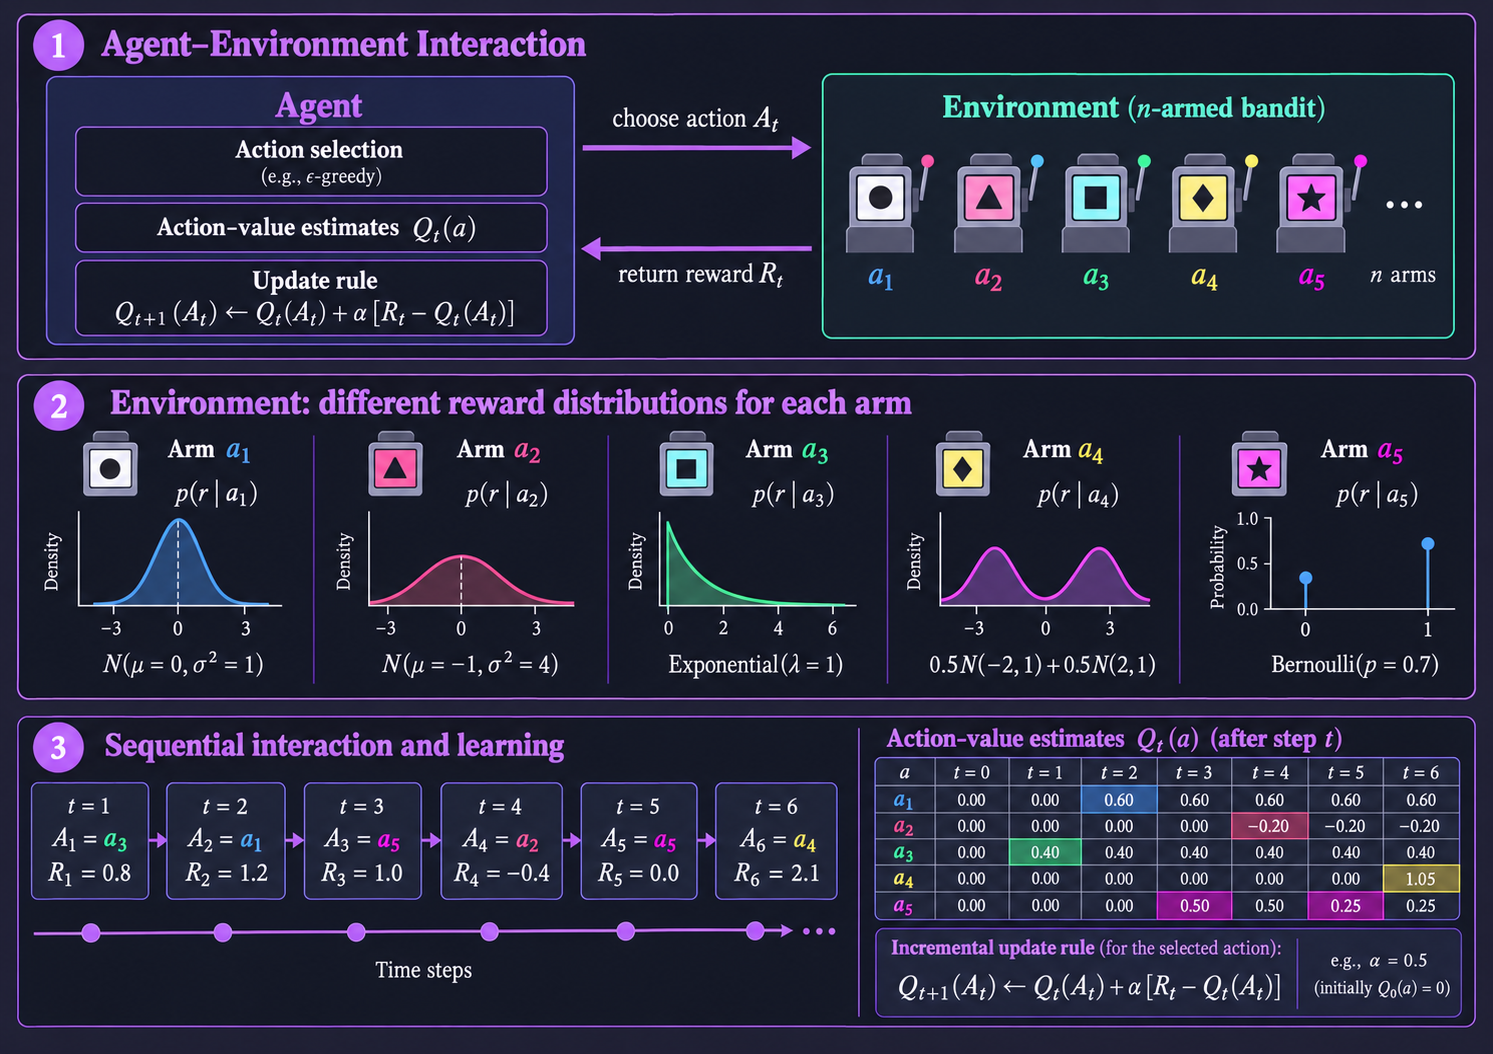

In [1]:
from IPython.display import Image, display, Markdown; display(Image(filename="multi-arm-bandit.png"))

## 1. The $n$-Armed Bandit problem

Each action $a$ has an unknown true value

$$
q_*(a) = \mathbb{E}[R_t \mid A_t=a].
$$

For each new bandit problem, we draw the 10 true action values from

$$
q_*(a) \sim \mathcal{N}(0,1).
$$

When the agent chooses action $a$, it receives a noisy reward

$$
R_t \sim \mathcal{N}(q_*(a), 1).
$$

The agent does **not** see $q_*(a)$. It only sees the rewards it receives.

### A schema for the experiment

We use a small in-memory SQLite database to make the objects in the experiment explicit and queryable.

The schema distinguishes four things:

- a **run**, which fixes one bandit instance and one policy parameter;
- a **run action summary**, which records the final true and learned values for each action in one run;
- a **step**, which records an action and reward during a run;
- a **policy metric**, which stores an aggregate learning curve computed from many persisted runs.

The SQL schema is the canonical data model. The SQLAlchemy classes immediately below are the
schema-derived Python interface that we use in the rest of the notebook.


In [1]:
from typing import TypeAlias

import matplotlib.pyplot as plt
import numpy as np
import numpy.typing as npt
from sqlalchemy import Float, ForeignKey, Integer, String, case, create_engine, func, select
from sqlalchemy.orm import DeclarativeBase, Mapped, Session, mapped_column

FloatArray: TypeAlias = npt.NDArray[np.float64]
IntArray: TypeAlias = npt.NDArray[np.int64]

SEED = 0
K = 10

SCHEMA_SQL = """
CREATE TABLE bandit_run (
    id INTEGER PRIMARY KEY,
    seed INTEGER NOT NULL,
    epsilon REAL NOT NULL,
    best_action INTEGER NOT NULL
);

CREATE TABLE bandit_run_action_summary (
    id INTEGER PRIMARY KEY,
    run_id INTEGER NOT NULL REFERENCES bandit_run(id),
    action_index INTEGER NOT NULL,
    true_value REAL NOT NULL,
    estimate REAL NOT NULL,
    times_selected INTEGER NOT NULL
);

CREATE TABLE bandit_step (
    id INTEGER PRIMARY KEY,
    run_id INTEGER NOT NULL REFERENCES bandit_run(id),
    step_index INTEGER NOT NULL,
    action_index INTEGER NOT NULL,
    reward REAL NOT NULL
);

CREATE TABLE bandit_policy_metric (
    id INTEGER PRIMARY KEY,
    policy_name TEXT NOT NULL,
    epsilon REAL NOT NULL,
    step_index INTEGER NOT NULL,
    average_reward REAL NOT NULL,
    optimal_action_rate REAL NOT NULL
);
"""

engine = create_engine("sqlite+pysqlite:///:memory:")


def create_schema() -> None:
    statements = [item.strip() for item in SCHEMA_SQL.split(";") if item.strip()]
    with engine.begin() as connection:
        for statement in statements:
            connection.exec_driver_sql(statement)


create_schema()
rng = np.random.default_rng(SEED)


In [2]:
class Base(DeclarativeBase):
    pass


class BanditRun(Base):
    __tablename__ = "bandit_run"

    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    seed: Mapped[int] = mapped_column(Integer)
    epsilon: Mapped[float] = mapped_column(Float)
    best_action: Mapped[int] = mapped_column(Integer)


class BanditRunActionSummary(Base):
    __tablename__ = "bandit_run_action_summary"

    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    run_id: Mapped[int] = mapped_column(ForeignKey("bandit_run.id"))
    action_index: Mapped[int] = mapped_column(Integer)
    true_value: Mapped[float] = mapped_column(Float)
    estimate: Mapped[float] = mapped_column(Float)
    times_selected: Mapped[int] = mapped_column(Integer)


class BanditStep(Base):
    __tablename__ = "bandit_step"

    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    run_id: Mapped[int] = mapped_column(ForeignKey("bandit_run.id"))
    step_index: Mapped[int] = mapped_column(Integer)
    action_index: Mapped[int] = mapped_column(Integer)
    reward: Mapped[float] = mapped_column(Float)


class BanditPolicyMetric(Base):
    __tablename__ = "bandit_policy_metric"

    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    policy_name: Mapped[str] = mapped_column(String)
    epsilon: Mapped[float] = mapped_column(Float)
    step_index: Mapped[int] = mapped_column(Integer)
    average_reward: Mapped[float] = mapped_column(Float)
    optimal_action_rate: Mapped[float] = mapped_column(Float)


In [3]:
def new_bandit(k: int, rng: np.random.Generator) -> FloatArray:
    """Create one stationary k-armed bandit."""
    return rng.normal(0.0, 1.0, size=k)


def reward_from(action: int, q_star: FloatArray, rng: np.random.Generator) -> float:
    """Sample one reward after choosing an action."""
    return float(rng.normal(q_star[action], 1.0))

A single bandit has 10 hidden action values. The best action is the one with the largest $q_*(a)$.

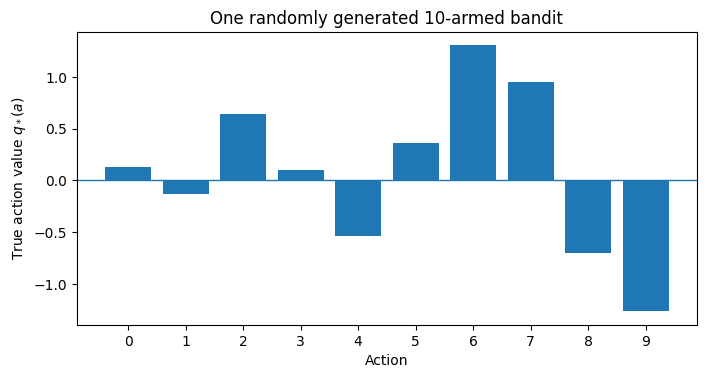

Best action for this hidden bandit: 6


In [4]:
demo_q_star = new_bandit(K, rng)

fig, ax = plt.subplots(figsize=(8, 3.8))
actions = np.arange(K)
ax.bar(actions, demo_q_star)
ax.axhline(0, linewidth=1)
ax.set_title("One randomly generated 10-armed bandit")
ax.set_xlabel("Action")
ax.set_ylabel("True action value $q_*(a)$")
ax.set_xticks(actions)
plt.show()

best_action = int(np.argmax(demo_q_star))
print(f"Best action for this hidden bandit: {best_action}")

## 2. What is a policy?

A **policy** tells the agent how to choose actions.

For a bandit, a policy is simply a probability distribution over the 10 actions:

$$
\pi(a) = \Pr(A_t=a).
$$

A **greedy** policy chooses an action with the largest current estimate $Q_t(a)$.

An **$\varepsilon$-greedy** policy is mostly greedy, but sometimes explores:

- with probability $1-\varepsilon$, choose a greedy action;
- with probability $\varepsilon$, choose uniformly at random from all actions.

This is the textbook convention. It means even the greedy action can be selected during the random exploration step.

The `epsilon_greedy_probs` function implements an **$\varepsilon$-greedy** policy.
- Its input is the current value estimates $Q_t(a)$ of each action at time step $t$ and the exploration rate `epsilon`.
- Its output is the probabilities of choosing each action under this policy.


The function uses these two NumPy operations.
- `np.full(size, value)` creates a NumPy array of a given size, with every element initialized to the same value.
- `np.flatnonzero(...)` returns the indices where the values are nonzero or `True`:

In [5]:
# q_values is the agent's current action value estimate Q_t(a)

# implements a policy pi that is epsilon-greedy
def epsilon_greedy_probs(q_values: FloatArray, epsilon: float) -> FloatArray:
    """Return the probability of choosing each action."""
    k = len(q_values)

    # uniformally distributes the epsilon across all actions equally.
    probabilities = np.full(k, epsilon / k)

    # figure out which action in Q_t(a) is the highest
    # returns the indices of actions that have the maximum action value estimate.
    greedy_actions = np.flatnonzero(q_values == q_values.max())

    # give these maximum-valued actions the greedy bonus of 1-epsilon
    greedy_bonus = (1.0 - epsilon) / len(greedy_actions)

    # for each action with the maximum Q_t(a), give it a greedy bonus of probabilty: (1 - epsilon) / (# of greedy action)
    probabilities[greedy_actions] += greedy_bonus
    
    return probabilities

Suppose the agent currently believes action 3 is best. With $\varepsilon=0.1$, most probability goes to action 3, while every action still has some chance of being tried.

In [6]:
# an example Q_t(a) action value estimates across all K actions
example_q = np.array([0.1, -0.2, 0.0, 0.8, 0.2, 0.1, -0.4, 0.3, 0.0, 0.1])

for epsilon in [0.0, 0.1]:
    probabilities = epsilon_greedy_probs(example_q, epsilon)
    print(f"epsilon = {epsilon}")
    print(np.round(probabilities, 3))
    print("sum =", probabilities.sum())
    print()

epsilon = 0.0
[0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
sum = 1.0

epsilon = 0.1
[0.01 0.01 0.01 0.91 0.01 0.01 0.01 0.01 0.01 0.01]
sum = 1.0



The `choose_action` function below selects an action by randomly sampling the probability distribution returned by the `epsilon_greedy_probs` policy.

In [7]:
def choose_action(
    q_values: FloatArray,
    epsilon: float,
    rng: np.random.Generator,
) -> int:
    """Sample an action from the epsilon-greedy policy."""

    # epsilon_greedy_probs is the policy
    probabilities = epsilon_greedy_probs(q_values, epsilon)
    
    # agent now selects an action based on the policy's action distribution
    return int(rng.choice(len(q_values), p=probabilities))

## 3. Estimating action values

The agent does not know $q_*(a)$, so it keeps an estimate $Q_t(a)$.

A simple estimate is the **sample average** of rewards observed after taking that action:

$$
Q_t(a)
=
\frac{\text{sum of rewards received after choosing }a}
     {\text{number of times }a\text{ was chosen}}.
$$

We can update the average incrementally:

$$
Q_t(a) \leftarrow Q_{t-1}(a) + \frac{1}{N}(R-Q_{t-1}(a)),
$$

where $N$ is the number of times that action has been selected.

In [8]:
# updates our action values Q_t(a) with the current step's selected action, reward to get Q_{t+1}(a)
def update_estimate(
    q_values: FloatArray,
    counts: IntArray,
    action: int,
    reward: float,
) -> None:
    """Update one sample-average action-value estimate in place."""
    counts[action] += 1
    step_size = 1.0 / counts[action]
    q_values[action] += step_size * (reward - q_values[action])

Now we have the complete learning loop for one bandit:

1. use the policy to choose an action,
2. receive a reward,
3. update the estimate of that action,
4. record the step in the database,
5. repeat.

After the run finishes, we store one `BanditRunActionSummary` row per action so we can inspect what the agent learned.


In [9]:
def run_one_bandit(
    db: Session,
    q_star: FloatArray,
    epsilon: float,
    num_steps: int,
    rng: np.random.Generator,
    seed: int,
) -> int:
    q_values = np.zeros(len(q_star), dtype=np.float64)
    counts = np.zeros(len(q_star), dtype=np.int64)
    best_action = int(np.argmax(q_star))

    run = BanditRun(seed=seed, epsilon=epsilon, best_action=best_action)
    db.add(run)
    db.flush()

    for step_index in range(num_steps):
        action = choose_action(q_values, epsilon, rng)
        reward = reward_from(action, q_star, rng)
        update_estimate(q_values, counts, action, reward)

        step = BanditStep(
            run_id=run.id,
            step_index=step_index,
            action_index=action,
            reward=reward,
        )
        db.add(step)

    for action_index in range(len(q_star)):
        summary = BanditRunActionSummary(
            run_id=run.id,
            action_index=action_index,
            true_value=float(q_star[action_index]),
            estimate=float(q_values[action_index]),
            times_selected=int(counts[action_index]),
        )
        db.add(summary)

    db.commit()
    return run.id


def load_run_action_summary(
    db: Session,
    run_id: int,
) -> tuple[FloatArray, FloatArray, IntArray]:
    statement = select(BanditRunActionSummary)
    statement = statement.where(BanditRunActionSummary.run_id == run_id)
    statement = statement.order_by(BanditRunActionSummary.action_index)
    rows = list(db.scalars(statement))

    true_values = np.array([row.true_value for row in rows], dtype=np.float64)
    estimates = np.array([row.estimate for row in rows], dtype=np.float64)
    counts = np.array([row.times_selected for row in rows], dtype=np.int64)
    return true_values, estimates, counts


### Watch one agent learn

A single run is noisy, but it lets us inspect what the agent has learned.

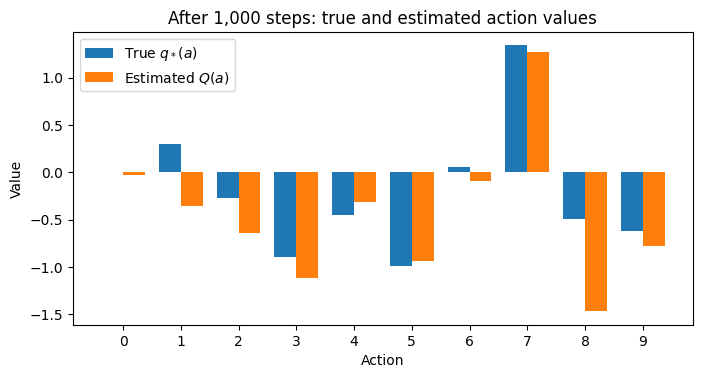

Times each action was chosen:
[ 10  16  11  10   5   9  14 909   5  11]


In [10]:
rng_one = np.random.default_rng(7)
q_star_one = new_bandit(K, rng_one)

with Session(engine) as db:
    run_id = run_one_bandit(db, q_star_one, 0.1, 1000, rng_one, 7)
    true_values, estimates, counts = load_run_action_summary(db, run_id)

fig, ax = plt.subplots(figsize=(8, 3.8))
actions = np.arange(K)
width = 0.38
ax.bar(actions - width / 2, true_values, width, label="True $q_*(a)$")
ax.bar(actions + width / 2, estimates, width, label="Estimated $Q(a)$")
ax.set_title("After 1,000 steps: true and estimated action values")
ax.set_xlabel("Action")
ax.set_ylabel("Value")
ax.set_xticks(actions)
ax.legend()
plt.show()

print("Times each action was chosen:")
print(counts)


## 4. How do we evaluate a policy?

One run can be lucky or unlucky. To compare policies, we repeat the same `run_one_bandit` experiment on many independently generated bandits.

Each run is persisted in the same data model we just used:

- `BanditRun` records the run-level settings and the true best action;
- `BanditStep` records every chosen action and reward;
- `BanditRunActionSummary` records what the agent learned about each action by the end of the run.

At time step $t$, we compute the average reward

$$
\bar{R}_t
=
\frac{1}{n}
\sum_{i=1}^{n} R_t^{(i)}.
$$

This estimates the expected reward of the policy at that point in learning.

We also track the **percentage of optimal actions**. Because `BanditRun.best_action` stores the true best action and `BanditStep.action_index` stores the action actually chosen, SQL can compute this directly across all persisted runs.

The important design point is that policy evaluation does **not** contain a second implementation of the learning algorithm. It reuses `run_one_bandit`, then aggregates the stored experiment data.


In [11]:
def evaluate_policy(
    db: Session,
    epsilon: float,
    num_runs: int,
    num_steps: int,
    k: int,
    seed: int,
) -> tuple[FloatArray, FloatArray]:
    run_ids: list[int] = []

    for run_index in range(num_runs):
        run_seed = seed + run_index
        run_rng = np.random.default_rng(run_seed)
        q_star = new_bandit(k, run_rng)

        run_id = run_one_bandit(
            db=db,
            q_star=q_star,
            epsilon=epsilon,
            num_steps=num_steps,
            rng=run_rng,
            seed=run_seed,
        )
        run_ids.append(run_id)

    optimal_action = case(
        (
            BanditStep.action_index == BanditRun.best_action,
            1.0,
        ),
        else_=0.0,
    )

    statement = (
        select(
            BanditStep.step_index,
            func.avg(BanditStep.reward).label("average_reward"),
            func.avg(optimal_action).label("optimal_action_rate"),
        )
        .select_from(BanditStep)
        .join(BanditRun, BanditStep.run_id == BanditRun.id)
        .where(BanditStep.run_id.in_(run_ids))
        .group_by(BanditStep.step_index)
        .order_by(BanditStep.step_index)
    )

    rows = db.execute(statement).all()

    average_rewards = np.array(
        [row.average_reward for row in rows],
        dtype=np.float64,
    )
    optimal_action_rate = np.array(
        [row.optimal_action_rate for row in rows],
        dtype=np.float64,
    )

    return average_rewards, optimal_action_rate


def store_policy_metrics(
    db: Session,
    policy_name: str,
    epsilon: float,
    average_rewards: FloatArray,
    optimal_action_rate: FloatArray,
) -> None:
    for step_index in range(len(average_rewards)):
        row = BanditPolicyMetric(
            policy_name=policy_name,
            epsilon=epsilon,
            step_index=step_index,
            average_reward=float(average_rewards[step_index]),
            optimal_action_rate=float(optimal_action_rate[step_index]),
        )
        db.add(row)

    db.commit()


We now compare the same three policies:

- greedy: $\varepsilon=0$
- $\varepsilon=0.01$
- $\varepsilon=0.1$

Because this version deliberately persists every run and every step in SQLite, we use 200 independent 10-armed bandit runs per policy, each lasting 1,000 steps. That produces 600,000 `BanditStep` rows across the three policies. Increase `NUM_EVALUATION_RUNS` to `2000` if you want smoother curves and do not mind the extra database work.


In [12]:
policies: dict[str, float] = {
    "greedy": 0.0,
    "epsilon = 0.01": 0.01,
    "epsilon = 0.1": 0.1,
}

NUM_EVALUATION_RUNS = 200
NUM_EVALUATION_STEPS = 1000

with Session(engine) as db:
    for index, (name, epsilon) in enumerate(policies.items()):
        average_rewards, optimal_rate = evaluate_policy(
            db=db,
            epsilon=epsilon,
            num_runs=NUM_EVALUATION_RUNS,
            num_steps=NUM_EVALUATION_STEPS,
            k=K,
            seed=100_000 * (index + 1),
        )
        store_policy_metrics(db, name, epsilon, average_rewards, optimal_rate)


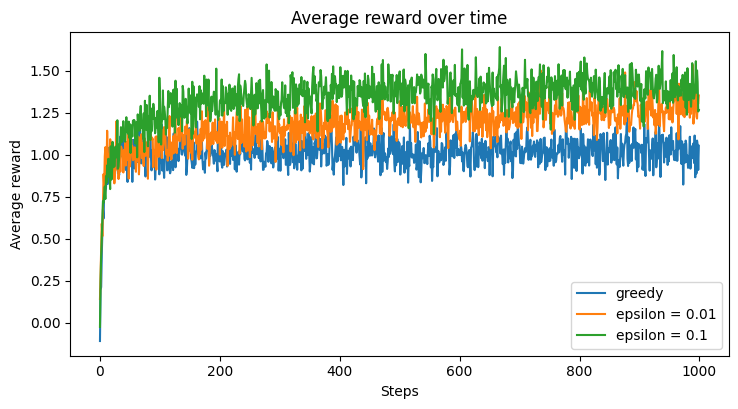

In [13]:
def load_metric_series(
    db: Session,
    policy_name: str,
) -> tuple[FloatArray, FloatArray]:
    statement = select(BanditPolicyMetric)
    statement = statement.where(BanditPolicyMetric.policy_name == policy_name)
    statement = statement.order_by(BanditPolicyMetric.step_index)
    rows = list(db.scalars(statement))
    rewards = np.array([row.average_reward for row in rows], dtype=np.float64)
    optimal = np.array([row.optimal_action_rate for row in rows], dtype=np.float64)
    return rewards, optimal


fig, ax = plt.subplots(figsize=(8.5, 4.2))
with Session(engine) as db:
    for name in policies:
        rewards, _ = load_metric_series(db, name)
        ax.plot(rewards, label=name)
ax.set_title("Average reward over time")
ax.set_xlabel("Steps")
ax.set_ylabel("Average reward")
ax.legend()
plt.show()

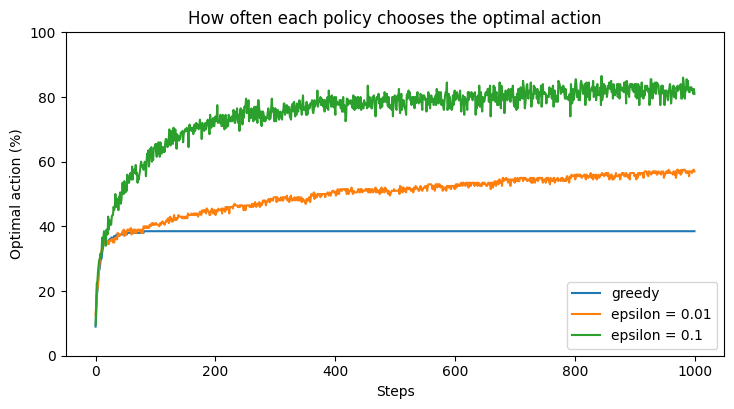

In [14]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
with Session(engine) as db:
    for name in policies:
        _, optimal_rate = load_metric_series(db, name)
        ax.plot(100.0 * optimal_rate, label=name)
ax.set_title("How often each policy chooses the optimal action")
ax.set_xlabel("Steps")
ax.set_ylabel("Optimal action (%)")
ax.set_ylim(0, 100)
ax.legend()
plt.show()

## 5. What should we learn from the comparison?

The key tension is **exploration versus exploitation**.

- A greedy policy exploits its current estimates, but an early noisy reward can make it commit to the wrong action.
- An $\varepsilon$-greedy policy keeps exploring, so it can correct early mistakes.
- More exploration is useful early, but exploration can also choose bad actions later.

The important idea is not that one value of $\varepsilon$ is always best. The important idea is that a policy controls how the agent balances what it currently believes with what it still needs to learn.

## 6. The whole agent in a few lines

The complete bandit learner is just:

```python
Q = np.zeros(10)
N = np.zeros(10, dtype=int)

for t in range(num_steps):
    action = choose_action(Q, epsilon)
    reward = reward_from(action, q_star)
    update_estimate(Q, N, action, reward)
```

Everything else in the notebook either defines the environment, makes the policy explicit, or evaluates the policy carefully.